## Action Offset Prediction with the Selected k

This experiment measures how well the K-Means clusters predict the action offset of new tasks.

Two types of action offset tasks are used:

- **Evenly spaced tasks**: Tasks with action offsets evenly spaced between −0.2 and +0.2. K-Means is fitted on their average hidden states, and each cluster gets the mean offset of the evenly spaced tasks it contains.
- **Random tasks**: Tasks with action offsets random between −0.2 and +0.2. They are not used for fitting and serve as test data.

The number of clusters is selected in `kmeans_k_selection.ipynb` with the prediction strength.

The error of the action offset prediction is measured with the Mean Absolute Error, each random task is assigned to its nearest cluster, and the mean offset of that cluster is used as the action offset prediction.

**Note:** for HalfCheetah, no k reaches the prediction strength threshold in `kmeans_k_selection.ipynb`, so there is no reproducible cluster structure (k = 1). To compare with the other systems, k = 2 is used here, whose mean prediction strength is just below the threshold. The results for k = 2 are for comparison only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys

sys.path.insert(0, os.path.abspath("../.."))
sys.path.insert(0, os.path.abspath(".."))
from analysis_utils import SYSTEMS, CHECKPOINT_DIR, set_seeds, load_model, collect_avg_hidden_states, task_parameters
from kmeans_utils import fit_kmeans

system = SYSTEMS["halfcheetah"]

num_repeats = 20
num_envs = 20
steps_per_env = 3000

set_seeds(42)

avg_hidden_states = np.load(
    CHECKPOINT_DIR / "halfcheetah_action_avg_hidden_states.npy"
)

offset_values = task_parameters(system, system.sample_tasks_eval(num_envs=len(avg_hidden_states)))

k_selection = np.load(CHECKPOINT_DIR / "halfcheetah_action_kmeans_k_selection.npz")
best_k = int(k_selection["best_k"])

# No k reaches the threshold for HalfCheetah (k = 1, no reproducible cluster structure).
# k = 2 is used for comparison only, its mean prediction strength is just below the threshold.
selected_k = best_k
if selected_k == 1:
    best_k = 2
comparison_note = ", below threshold, for comparison only" if selected_k == 1 else ""
k_values = [int(k) for k in k_selection["k_values"]]

print(avg_hidden_states.shape)
print(f"Selected k = {selected_k}, used k = {best_k}")

(20, 256)
Selected k = 1, used k = 2


In [2]:
# Create the RL2 model and load the trained weights
model = load_model(system)

### Collect Hidden States of the Random Tasks

All `num_repeats × num_envs` random tasks are rolled out once before the k search starts. Every random task is played for `steps_per_env` steps. The k search reuses their hidden states, so no new rollouts are needed for each k.

In [3]:
# For MAE calculation
all_random_offset_values = np.zeros((num_repeats, num_envs))

# Store the average hidden state of every random task
all_random_avg_hidden_states = np.zeros(
    (num_repeats, num_envs, model.feat_extractor.h_dim),
    dtype=avg_hidden_states.dtype # PyTorch calculates avg hidden state in float32
)

baseline_prediction = np.median(offset_values) # = 0.0 (evenly spaced offsets)

# Storage for MAE per repetition
baseline_maes = np.zeros(num_repeats)

for repeat in range(num_repeats):

    random_env_configs = system.sample_tasks_train(num_envs=num_envs)
    random_envs = system.make_envs(random_env_configs)

    try:
        random_offset_values = task_parameters(system, random_env_configs)

        # Play every random task and average its hidden state over all steps
        all_random_avg_hidden_states[repeat] = collect_avg_hidden_states(
            model, system, random_envs, seed=1000 + repeat, steps=steps_per_env
        )
        all_random_offset_values[repeat] = random_offset_values

        # Calculate the constant baseline prediction error
        baseline_maes[repeat] = np.mean(
            np.abs(random_offset_values - baseline_prediction)
        )

        print(f"Repetition {repeat + 1}/{num_repeats} completed")

    finally:
        random_envs.close()

print(f"{num_repeats * num_envs} random tasks collected "
      f"({num_repeats} repetitions x {num_envs} tasks)")

Repetition 1/20 completed
Repetition 2/20 completed
Repetition 3/20 completed
Repetition 4/20 completed
Repetition 5/20 completed
Repetition 6/20 completed
Repetition 7/20 completed
Repetition 8/20 completed
Repetition 9/20 completed
Repetition 10/20 completed
Repetition 11/20 completed
Repetition 12/20 completed
Repetition 13/20 completed
Repetition 14/20 completed
Repetition 15/20 completed
Repetition 16/20 completed
Repetition 17/20 completed
Repetition 18/20 completed
Repetition 19/20 completed
Repetition 20/20 completed
400 random tasks collected (20 repetitions x 20 tasks)


### MAE for every k

For every k tested in `kmeans_k_selection.ipynb`, the following steps are performed:

1. **Clustering:** K-Means is fitted on the average hidden states of the evenly spaced tasks. It is run with multiple initializations (`n_init`), and the solution with the lowest inertia is used, so the result does not depend on the initial centroids. Each cluster gets the mean action offset of the evenly spaced tasks it contains.
2. **Mean MAE:** the hidden state of each random task is assigned to the nearest cluster centroid, and the mean offset of that cluster is used as the action offset prediction. The absolute errors between actual and predicted offset are averaged per repetition (MAE) and then over all repetitions (Mean MAE).

Only the selected k is used for the action offset prediction below. The other k values are listed for comparison.

> **Note:** The clusters are fitted only on the hidden states of the evenly spaced tasks, not on the random tasks. The evenly spaced tasks cover the whole offset range uniformly, so no offset range is over- or underrepresented, and they are identical in every run. The random tasks are only assigned to the existing clusters and serve as unseen test data.

In [4]:
def evaluate_k(k):
    # Fit K-Means on the hidden states of the evenly spaced tasks
    kmeans = fit_kmeans(avg_hidden_states, k)
    cluster_assignments = kmeans.labels_

    # Stop if a cluster is empty (wont be better for more k's)
    if len(np.unique(cluster_assignments)) < k:
        return None

    # Calculate the mean offset of the evenly spaced tasks in each cluster
    cluster_offset_means = np.array([
        np.mean(offset_values[cluster_assignments == cluster])
        for cluster in range(k)
    ])

    # Storage for MAE per repetition
    cluster_maes = np.zeros(num_repeats)

    for repeat in range(num_repeats):

        # Assign the hidden states of the random tasks to the existing clusters
        random_cluster_assignments = kmeans.predict(all_random_avg_hidden_states[repeat])

        # Predict action offsets using the cluster_offset_means
        predicted_offset = cluster_offset_means[random_cluster_assignments]

        cluster_maes[repeat] = np.mean(
            np.abs(all_random_offset_values[repeat] - predicted_offset)
        )

    return kmeans, cluster_assignments, cluster_offset_means, cluster_maes


tested_k_values = []
mae_per_k = []
kmeans_models = {}
cluster_assignments_per_k = {}
cluster_offset_means_per_k = {}

for k in k_values:

    result = evaluate_k(k)

    if result is None:
        print(f"k = {k}: K-Means found fewer than {k} clusters, skipped.")
        continue

    kmeans, cluster_assignments, cluster_offset_means, cluster_maes = result

    tested_k_values.append(k)
    mae_per_k.append(cluster_maes)
    kmeans_models[k] = kmeans
    cluster_assignments_per_k[k] = cluster_assignments
    cluster_offset_means_per_k[k] = cluster_offset_means

    print(f"k = {k}: Mean MAE = {np.mean(cluster_maes):.3f}")

assert best_k in kmeans_models, f"The selected k = {best_k} could not be evaluated"

k = 2: Mean MAE = 0.050
k = 3: Mean MAE = 0.035
k = 4: Mean MAE = 0.028
k = 5: Mean MAE = 0.027
k = 6: Mean MAE = 0.025
k = 7: Mean MAE = 0.025
k = 8: Mean MAE = 0.025
k = 9: Mean MAE = 0.024
k = 10: Mean MAE = 0.024


In [5]:
# Combine the MAEs into one array with shape (num_repeats, number of tested k)
mae_results = np.column_stack(mae_per_k)

# Calculate mean and standard deviation across repetitions
mean_mae = np.mean(mae_results, axis=0)
std_mae = np.std(mae_results, axis=0, ddof=1)

baseline_mean = np.mean(baseline_maes)
baseline_std = np.std(baseline_maes, ddof=1)

print(f"{'k':>3} | {'Mean MAE':>8} | {'Std':>5}")

for j, k in enumerate(tested_k_values):
    marker = ("  <- used for comparison" if selected_k == 1 else "  <- selected") if k == best_k else ""
    print(f"{k:>3} | {mean_mae[j]:>8.3f} | {std_mae[j]:>5.3f}{marker}")

print(
    f"\nBaseline: Mean MAE = {baseline_mean:.3f}, "
    f"Std = {baseline_std:.3f}"
)

  k | Mean MAE |   Std
  2 |    0.050 | 0.007  <- used for comparison
  3 |    0.035 | 0.003
  4 |    0.028 | 0.005
  5 |    0.027 | 0.005
  6 |    0.025 | 0.005
  7 |    0.025 | 0.005
  8 |    0.025 | 0.005
  9 |    0.024 | 0.005
 10 |    0.024 | 0.005

Baseline: Mean MAE = 0.102, Std = 0.010


### Offset Ranges of the Selected k

Each cluster of the selected k is listed with the action offsets of the evenly spaced tasks it contains.

The figure below shows how well the selected k predicts the offset of all random tasks. The random tasks of all repetitions are grouped by their actual action offset:

- **(a)** the mean predicted action offset in each offset range. Each cluster predicts the mean offset of its evenly spaced tasks, so the line follows the dashed line of a perfect prediction in steps.
- **(b)** the mean absolute error in each offset range, compared to the constant baseline that always predicts 0.

In [6]:
best_cluster_assignments = cluster_assignments_per_k[best_k]
best_cluster_offset_means = cluster_offset_means_per_k[best_k]

print(f"Clusters for k = {best_k}, sorted by mean offset:\n")

# Sort the clusters by their mean offset for readability
for cluster in np.argsort(best_cluster_offset_means):
    cluster_offsets = offset_values[best_cluster_assignments == cluster]

    print(
        f"Cluster {cluster}: Mean Offset = {best_cluster_offset_means[cluster]:6.3f} | "
        f"Range = {cluster_offsets.min():6.3f} to {cluster_offsets.max():6.3f} | "
        f"Offsets = {np.round(cluster_offsets, 3)}"
    )

Clusters for k = 2, sorted by mean offset:

Cluster 1: Mean Offset = -0.126 | Range = -0.200 to -0.053 | Offsets = [-0.2   -0.179 -0.158 -0.137 -0.116 -0.095 -0.074 -0.053]
Cluster 0: Mean Offset =  0.084 | Range = -0.032 to  0.200 | Offsets = [-0.032 -0.011  0.011  0.032  0.053  0.074  0.095  0.116  0.137  0.158
  0.179  0.2  ]


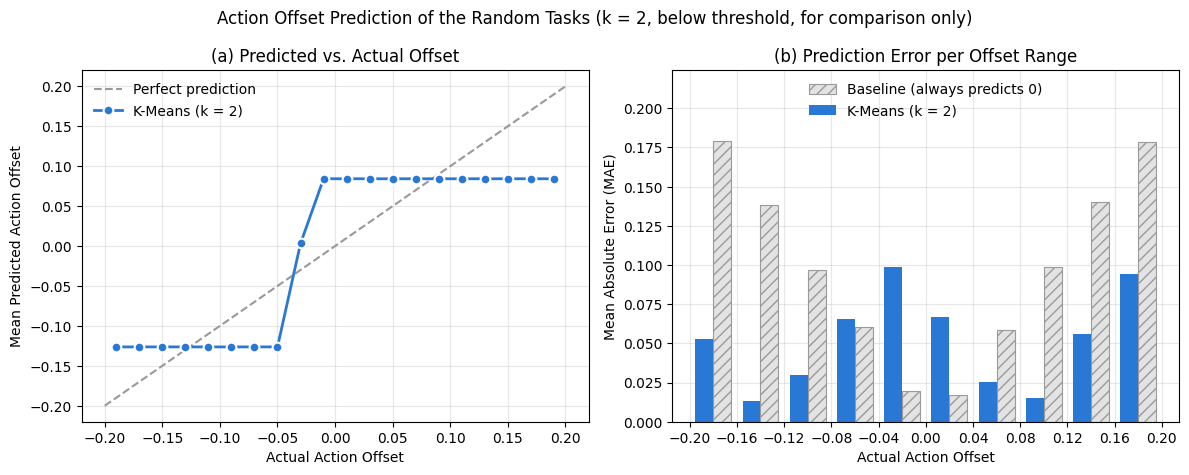

In [7]:
# Blue for K-Means, gray for references
KMEANS_COLOR = "#2a78d6"
REFERENCE_COLOR = "#999999"
# Lighter, hatched gray for the baseline bars, so they are not confused with the perfect prediction line
BASELINE_FILL_COLOR = "#e3e3e3"
BASELINE_HATCH_COLOR = "#9a9a9a"

best_kmeans = kmeans_models[best_k]
best_cluster_offset_means = cluster_offset_means_per_k[best_k]

# All random tasks of all repetitions as one flat list
flat_random_hidden_states = all_random_avg_hidden_states.reshape(-1, all_random_avg_hidden_states.shape[-1])
flat_random_offset_values = all_random_offset_values.reshape(-1)

# Predict the offset of every random task with the mean offset of its cluster
flat_random_cluster_assignments = best_kmeans.predict(flat_random_hidden_states)
flat_predicted_offset = best_cluster_offset_means[flat_random_cluster_assignments]
flat_kmeans_errors = np.abs(flat_random_offset_values - flat_predicted_offset)
# The baseline always predicts the median of the evenly spaced offsets (0)
flat_baseline_errors = np.abs(flat_random_offset_values - np.median(offset_values))


def mean_per_offset_range(values, bin_edges):
    # Mean of the values of all random tasks whose actual offset lies in each offset range
    bin_index = np.clip(np.digitize(flat_random_offset_values, bin_edges) - 1, 0, len(bin_edges) - 2)
    return np.array([
        np.mean(values[bin_index == b]) if np.any(bin_index == b) else np.nan
        for b in range(len(bin_edges) - 1)
    ])


# (a) Fine offset ranges of 0.02 for the prediction line
line_edges = np.linspace(-0.2, 0.2, 21)
line_centers = (line_edges[:-1] + line_edges[1:]) / 2
mean_predicted_per_range = mean_per_offset_range(flat_predicted_offset, line_edges)

# (b) Offset ranges of 0.04 for the error bars
bar_edges = np.linspace(-0.2, 0.2, 11)
bar_centers = (bar_edges[:-1] + bar_edges[1:]) / 2
kmeans_mae_per_range = mean_per_offset_range(flat_kmeans_errors, bar_edges)
baseline_mae_per_range = mean_per_offset_range(flat_baseline_errors, bar_edges)

# Plotting
plot_name = "halfcheetah_kmeans_offset_prediction.png"
save_path = os.path.join("diagrams", plot_name)
os.makedirs(os.path.dirname(save_path), exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# (a) Mean predicted offset per offset range
axes[0].plot(
    [-0.2, 0.2], [-0.2, 0.2],
    color=REFERENCE_COLOR, linewidth=1.5, linestyle="--", label="Perfect prediction"
)
axes[0].plot(
    line_centers, mean_predicted_per_range,
    color=KMEANS_COLOR, linewidth=2,
    marker="o", markersize=7, markeredgecolor="white", markeredgewidth=1.5,
    label=f"K-Means (k = {best_k})"
)
axes[0].set_xlim(-0.22, 0.22)
axes[0].set_ylim(-0.22, 0.22)
axes[0].set_xlabel("Actual Action Offset")
axes[0].set_ylabel("Mean Predicted Action Offset")
axes[0].set_title("(a) Predicted vs. Actual Offset")
axes[0].legend(loc="upper left", frameon=False)

# (b) Mean absolute error per offset range, K-Means next to the baseline
# The baseline is drawn first, so it is listed first in the legend, as in (a)
bar_width = 0.0152
axes[1].bar(
    bar_centers + bar_width / 2, baseline_mae_per_range,
    width=bar_width, facecolor=BASELINE_FILL_COLOR,
    edgecolor=BASELINE_HATCH_COLOR, linewidth=0.8, hatch="///",
    label="Baseline (always predicts 0)"
)
axes[1].bar(
    bar_centers - bar_width / 2, kmeans_mae_per_range,
    width=bar_width, color=KMEANS_COLOR, label=f"K-Means (k = {best_k})"
)
axes[1].set_xticks(bar_edges)
axes[1].set_xticklabels([f"{e:.2f}".replace("-", "−") for e in bar_edges])
axes[1].set_xlabel("Actual Action Offset")
axes[1].set_ylabel("Mean Absolute Error (MAE)")
axes[1].set_title("(b) Prediction Error per Offset Range")
axes[1].legend(loc="upper center", frameon=False)
axes[1].set_ylim(0, np.nanmax([kmeans_mae_per_range, baseline_mae_per_range]) * 1.25)

for ax in axes:
    ax.grid(alpha=0.3)
    ax.set_axisbelow(True)

fig.suptitle(f"Action Offset Prediction of the Random Tasks (k = {best_k}{comparison_note})")
fig.tight_layout()
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

In [8]:
# Save the results and corresponding rollout data.
np.savez(
    CHECKPOINT_DIR / "halfcheetah_action_kmeans_repeated_eval.npz",
    k_values=np.array(tested_k_values),
    best_k=best_k,
    selected_k=selected_k,
    mae_results=mae_results,
    baseline_maes=baseline_maes,
    random_offset_values=all_random_offset_values,
    random_avg_hidden_states=all_random_avg_hidden_states
)

print("Repeated evaluation results saved.")

Repeated evaluation results saved.
